# 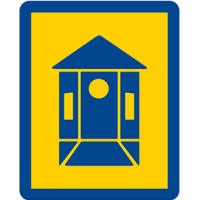

#**Actividad / Parcial (Segundo Cohorte)**<br>
**Electiva III - Introducción a Ciencia de Datos (Extracción de datos mediante webscraping)**<br>

**Institución Universitaria Colegio Mayor del Cauca**<br>
**2026 - II**<br>

# *Extracción de datos mediante webscraping.*

***
## Instrucciones Generales:
- Esta actividad debe ser desarrollada utilizando el lenguaje de programación Python, en este mismo Notebook.
- El Notebook debe estar  ordenado, seguir buenas prácticas de escritura y programación, se vale agregar comentarios cuando se requiera o un texto descriptivo si lo consideran necesario.
- La actividad deberá ser sustentada por todos los miembros del grupo/equipo.
- El Notebook ya contiene algunas celdas marcadas con el comentario `#código de inicio`. Estas celdas han sido incluidas como ayuda para el desarrollo de la actividad, y pueden ser ejecutadas tal como están.
- Las celdas marcadas como `#completar código` tienen un código parcial que debe ser completado para poder ser ejecutado. Ud debe agregar todas las líneas o bloques de código necesarios para desarrollar correctamente cada punto de la tarea. También puede eliminar estas celdas y partir el código desde cero si le resulta más conveniente.

## 📊 Introducción

En los últimos años, la **ciencia de datos** se ha consolidado como una de las disciplinas más demandadas en el ámbito tecnológico y empresarial. Según el informe "*The Future of Jobs Report 2023*" del **Foro Económico Mundial**, los roles relacionados con análisis de datos y aprendizaje automático figuran entre los más prometedores en cuanto a crecimiento y transformación del mercado laboral global.

🔗 [The Future of Jobs Report 2025 – World Economic Forum](https://www.weforum.org/publications/the-future-of-jobs-report-2025/)

🔗 [Davos 2026: Claves sobre la transformación del empleo y las habilidades – World Economic Forum](https://es.weforum.org/stories/jobs-and-the-future-of-work/davos-2026-esto-es-lo-que-hay-que-saber-sobre-la-transformacion-del-empleo-y-las-habilidades)

Este auge responde a la creciente necesidad de las organizaciones de interpretar grandes volúmenes de datos para tomar decisiones informadas, optimizar procesos y generar ventajas competitivas. Como consecuencia, las vacantes para perfiles como *científicos de datos*, *analistas de datos* y *especialistas en inteligencia artificial* han aumentado significativamente, especialmente en sectores como tecnología, salud, finanzas y comercio.

Aunque muchas de las estadísticas y proyecciones provienen de estudios realizados en Norteamérica y Europa, **América Latina** también está experimentando una expansión en este campo. Diversas consultoras y portales como *Michael Page* destacan el crecimiento sostenido de la demanda por talento en datos en países como Colombia, México, Brasil y Chile.

En este contexto, usted ha sido asignado al diseño de un estudio que explore el estado actual del mercado laboral con enfoque en Ciencia de Datos e IA en América Latina. Como primer paso, se requiere construir una base de datos con vacantes extraídas directamente de portales abiertos de empleo, como **LinkedIn Jobs**, mediante técnicas de *web scraping*.

🔗 [Portal de empleos: LinkedIn Jobs](https://www.linkedin.com/jobs/)

>*Este ejercicio fue inspirado por diversos recursos didácticos disponibles en línea y adaptado con fines académicos.*





### 🎯 Contexto y Cobertura Geográfica

Para el desarrollo de este estudio, es fundamental que el análisis no se limite a una sola región. El objetivo es estructurar una investigación comparativa que abarque el mercado laboral de **todo el continente americano**, integrando tanto la dinámica de **Norteamérica** como el crecimiento emergente en los países de **América Latina**.

A continuación, definiremos de forma aleatoria el país de análisis y el rol específico en Ciencia de Datos o IA en el que enfocarás tu extracción de datos y posterior análisis.

### 🎲 Selección Aleatoria de País y Cargo/Enfoque

Ejecuta la siguiente celda de código para asignar de forma aleatoria el **país** de América y la **posición/enfoque** que utilizarás como parámetros para tu búsqueda de empleo en LinkedIn.

¡Cada ejecución generará una combinación diferente para tu equipo!

Elige una que sea de tu interés

In [ ]:
import random
from urllib.parse import quote_plus

# Lista seleccionada de los países con mayor mercado laboral y relevancia económica en América
paises_america = [
    'Argentina',
    'Brasil',
    'Canadá',
    'Chile',
    'Colombia',
    'Costa Rica',
    'Ecuador',
    'Estados Unidos',
    'México',
    'Perú',
    'Uruguay'
]

# Lista ampliada de cargos, enfoques y palabras clave en Ciencia de Datos, IA y tecnologías emergentes
cargos_enfoque = [
    'Data Scientist',
    'Data Analyst',
    'Machine Learning Engineer',
    'AI Specialist',
    'Data Engineer',
    'Business Intelligence Analyst',
    'AI Agents Specialist',
    'NLP Engineer (Procesamiento de Lenguaje Natural)',
    'Computer Vision Engineer',
    'MLOps Engineer',
    'Deep Learning Architect',
    'Prompt Engineer & AI Generativa',
    'Data Architect',
    'AI Product Manager'
]

# Selección aleatoria
pais_asignado = random.choice(paises_america)
cargo_asignado = random.choice(cargos_enfoque)

# Codificación segura de caracteres especiales (por ejemplo, '&' en 'Prompt Engineer & AI Generativa' o espacios)
# con quote_plus para evitar que rompan la URL o generen errores HTTP 500 en el servidor
position = quote_plus(cargo_asignado)
location = quote_plus(pais_asignado)

# Generamos la URL de búsqueda personalizada
url_search = f'https://www.linkedin.com/jobs/search/?keywords={position}&location={location}'

print('🎯 Cargo asignado:', cargo_asignado)
print('📍 País asignado:', pais_asignado)
print('🔗 URL de Búsqueda sugerida para el estudio:')
print(url_search)


🔗 URL de Búsqueda sugerida para el estudio:
https://www.linkedin.com/jobs/search/?keywords=Prompt+Engineer+&+AI+Generativa&location=Colombia


In [ ]:
#código de inicio
import requests
from bs4 import BeautifulSoup
import pandas as pd

In [ ]:
# Imports adicionales que usaremos a lo largo del notebook
import re
import time
import random
import unicodedata
from urllib.parse import quote_plus

import matplotlib.pyplot as plt

**1.** Ingrese a la url definida anteriormente y realice una búsqueda de empleos para el **cargo/posición y país**  que usted haya seleccionado (*Puede seleccionar la combinación que usted prefiera o generar la url de forma manual sin tener en cuenta el paso anterior*).

Se sugiere abrir la url en su navegador en modo incognito para evitar que les solicite autenticación y/o que presenten inconvenientes al inspeccionar los datos.

Inspeccione y analice el código fuente de la página de resultados, para entender la estructura de su código HTML.

En base a su inspección del código HTML, responda: ¿Qué elemento del código le permite llegar exactamente a la lista de anuncios de empleo? Haga una descripción y agregue pantallazos de su análisis.

**Respuesta al punto 1 – Tema de estudio y análisis del HTML**

**Hipótesis del equipo:** El panorama para desarrolladores *junior* (frontend, backend y full stack) en Colombia es significativamente desfavorable: la oferta visible de vacantes de nivel de entrada es minoritaria frente a la demanda abrumadora de perfiles intermedios (*Mid-level*) y avanzados (*Senior/Lead*).

**Búsqueda elegida:** Palabra clave general `Desarrollador` / `Developer` con ubicación `Colombia` (sin fijar un único rol o tecnología, permitiendo recolectar el espectro amplio del sector tecnológico nacional y posteriormente clasificar las ramas frontend, backend, full stack y móvil a partir del título).

**Elemento que lleva a la lista de anuncios:** Al inspeccionar el árbol de documentos (DOM) de la página pública de resultados de LinkedIn (clic derecho → *Inspeccionar* en el navegador), se identifica que el contenedor principal de los resultados de empleo es una lista no ordenada con la etiqueta:

```html
<ul class="jobs-search__results-list">
```

Cada oferta individual de empleo se estructura dentro de un elemento de lista `<li>`, que a su vez contiene una tarjeta estructurada `<div class="base-card ...">` provista del atributo `data-entity-urn` (que contiene el identificador numérico único de la vacante).

Dentro de cada tarjeta, los datos clave se distribuyen en los siguientes selectores HTML y clases CSS:

| Dato Requerido | Etiqueta HTML | Clase CSS / Atributo Selector | Función en el DOM |
|---|---|---|---|
| **Título del puesto** | `<h3>` | `class="base-search-card__title"` | Nombre visible del cargo publicado por la empresa. |
| **Nombre de la empresa** | `<h4>` | `class="base-search-card__subtitle"` | Nombre de la compañía u organización contratante. |
| **Localización** | `<span>` | `class="job-search-card__location"` | Ciudad, departamento/región o país de la vacante. |
| **URL del anuncio** | `<a>` | `class="base-card__full-link"` (atributo `href`) | Enlace directo a la oferta individual (permite extraer el ID único). |
| **Fecha de publicación** | `<time>` | `class="job-search-card__listdate"` (atributo `datetime`) | Marca temporal en formato estándar ISO (`AAAA-MM-DD`). |

### Diagrama de la Jerarquía DOM inspeccionada:
```text
ul.jobs-search__results-list (Contenedor principal)
 └── li (Elemento individual de anuncio)
      └── div.base-card (Atributo data-entity-urn="urn:li:jobPosting:ID")
           ├── h3.base-search-card__title          --> Título de la vacante
           ├── h4.base-search-card__subtitle       --> Compañía contratante
           ├── span.job-search-card__location      --> Localización geográfica
           ├── a.base-card__full-link [href]       --> Enlace URL completo
           └── time.job-search-card__listdate      --> Fecha ISO de publicación
```

> **Nota técnica de inspección:** En entornos de inspección web, es crucial verificar periódicamente los nombres de clase, ya que LinkedIn actualiza sus plantillas HTML para dificultar el scraping automatizado. El uso de selectores semánticos (`find` y `class_`) y la extracción del identificador único `data-entity-urn` garantizan una extracción robusta y evitan el registro de duplicados al paginar.


In [ ]:
# Parámetros elegidos por el equipo (el punto 1 permite no usar el sorteo aleatorio)
KEYWORDS = "Desarrollador"   # en el punto 5 también usaremos "Developer"
LOCATION = "Colombia"

url_search = (
    "https://www.linkedin.com/jobs/search/"
    f"?keywords={quote_plus(KEYWORDS)}&location={quote_plus(LOCATION)}"
)
print("🔗 URL de búsqueda:", url_search)

🔗 URL de búsqueda: https://www.linkedin.com/jobs/search/?keywords=Desarrollador&location=Colombia


#### 2. Extraiga la lista de anuncios de trabajo arrojados por su búsqueda en Linkedin.

In [ ]:
# Código de inicio y optimización de cabeceras HTTP
# Para evitar bloqueos (HTTP 403, 429) o fallos de backend (HTTP 500) por parte del WAF/Akamai de LinkedIn,
# es indispensable enviar cabeceras completas que simulen con alta fidelidad un navegador web real y moderno:

head = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36',
    'Accept': 'text/html,application/xhtml+xml,application/xml;q=0.9,image/avif,image/webp,image/apng,*/*;q=0.8',
    'Accept-Language': 'es-ES,es;q=0.9,en;q=0.8',
    'Accept-Encoding': 'gzip, deflate, br',
    'Connection': 'keep-alive',
    'Upgrade-Insecure-Requests': '1',
    'Sec-Fetch-Dest': 'document',
    'Sec-Fetch-Mode': 'navigate',
    'Sec-Fetch-Site': 'none',
    'Sec-Fetch-User': '?1',
}


In [ ]:
import requests

In [ ]:
# Punto 2 – Request a la página de resultados
# (head viene de la celda de "código de inicio" anterior: define el User-Agent)
response = requests.get(url_search, headers=head, timeout=30)
print(f"Estado de la respuesta: {response.status_code}")

Estado de la respuesta: 200


In [ ]:
# "Sopa" de HTML: BeautifulSoup convierte el texto HTML en un árbol por el que podemos navegar
soup = BeautifulSoup(response.text, "html.parser")

# Según la inspección del punto 1, la lista de empleos es el <ul class="jobs-search__results-list">
lista = soup.find("ul", class_="jobs-search__results-list")

if lista is None:
    print("⚠️ No se encontró la lista de empleos. Posibles causas: bloqueo (código distinto de 200),")
    print("   página de login o cambio de nombres de clase. Primeros caracteres recibidos:")
    print(response.text[:500])
    anuncios = []
else:
    anuncios = lista.find_all("li")   # cada <li> es un anuncio

print(f"Anuncios encontrados en la primera página: {len(anuncios)}")

Anuncios encontrados en la primera página: 60


#### 3. Seleccione por ahora sólo el primer anuncio de la lista, y extraiga la información de:  título del trabajo, nombre de la compañía, localización, y URL del anuncio.

Nota: Por localización se entiende la ciudad, comuna o municipio indicado en el anuncio.

In [ ]:
# Punto 3 – Primer anuncio de la lista
def texto(elemento):
    """Devuelve el texto limpio de una etiqueta, o None si la etiqueta no existe."""
    return elemento.get_text(strip=True) if elemento else None


primero = anuncios[0]

titulo = texto(primero.find("h3", class_="base-search-card__title"))
empresa = texto(primero.find("h4", class_="base-search-card__subtitle"))
ubicacion = texto(primero.find("span", class_="job-search-card__location"))
enlace = primero.find("a", class_="base-card__full-link")
url_anuncio = enlace["href"] if enlace else None

print("Título:   ", titulo)
print("Empresa:  ", empresa)
print("Ubicación:", ubicacion)
print("URL:      ", url_anuncio)

Título:    Ruby Fullstack Developer - Remote Work | REF#160230
Empresa:   BairesDev
Ubicación: Pereira, Risaralda, Colombia
URL:       https://co.linkedin.com/jobs/view/ruby-fullstack-developer-remote-work-ref%23160230-at-bairesdev-4258058996?position=1&pageNum=0&refId=PICqoyIH8BuB0Aae5zh7gA%3D%3D&trackingId=qtpM86d4YT6QE1BPlnF6iA%3D%3D


#### 4. En base a los puntos anteriores, programe una rutina para extraer la información de localización,  título del trabajo, nombre de la compañía, localización, y URL del anuncio para todos los trabajos arrojados por su búsqueda de Linkedin, y almacenar los datos en un dataframe de pandas.

In [ ]:
# Punto 4 – Rutina para todos los anuncios de la página y DataFrame de pandas
def parsear_anuncio(li):
    """Convierte un <li> de LinkedIn en un diccionario con los datos del anuncio."""
    enlace = li.find("a", class_="base-card__full-link")
    url = enlace["href"].split("?")[0] if enlace and enlace.get("href") else None

    # Identificador único de la oferta (sirve para eliminar duplicados más adelante)
    id_oferta = None
    tarjeta = li.find("div", attrs={"data-entity-urn": True})
    if tarjeta:
        id_oferta = tarjeta["data-entity-urn"].split(":")[-1]
    elif url:
        m = re.search(r"(\d{6,})/?$", url)
        id_oferta = m.group(1) if m else None

    fecha = li.find("time")
    return {
        "id_oferta": id_oferta,
        "titulo": texto(li.find("h3", class_="base-search-card__title")),
        "empresa": texto(li.find("h4", class_="base-search-card__subtitle")),
        "ubicacion": texto(li.find("span", class_="job-search-card__location")),
        "url": url,
        "fecha_publicacion": fecha.get("datetime") if fecha else None,
    }


df_pagina1 = pd.DataFrame([parsear_anuncio(li) for li in anuncios])
print(f"Filas: {df_pagina1.shape[0]} | Columnas: {df_pagina1.shape[1]}")
df_pagina1.head(10)

Filas: 60 | Columnas: 6


,id_oferta,titulo,empresa,ubicacion,url,fecha_publicacion
0,4258058996,Ruby Fullstack Developer - Remote Work | REF#1...,BairesDev,"Pereira, Risaralda, Colombia",https://co.linkedin.com/jobs/view/ruby-fullsta...,2025-06-26
1,4462075383,Java & Kotlin Developer – Spring Framework - R...,BairesDev,"Bogota, D.C., Capital District, Colombia",https://co.linkedin.com/jobs/view/java-kotlin-...,2026-09-08
2,4453388050,Fullstack Software Engineer - [Ingeniero de So...,Clara,"Bogota, D.C., Capital District, Colombia",https://co.linkedin.com/jobs/view/fullstack-so...,2026-08-12
3,4387995641,Agentic Elixir Engineer - Remote - Colombia,FullStack,"Medellin, Antioquia, Colombia",https://co.linkedin.com/jobs/view/agentic-elix...,2026-10-23
4,4428704273,Senior Python Developer,Endava,"Bogota, D.C., Capital District, Colombia",https://co.linkedin.com/jobs/view/senior-pytho...,2026-09-28
5,4475165063,Senior Python Developer,EPAM Systems,Colombia,https://co.linkedin.com/jobs/view/senior-pytho...,2026-10-07
6,4387995645,Agentic Elixir Engineer - Remote - Colombia,FullStack,"Manizales, Caldas, Colombia",https://co.linkedin.com/jobs/view/agentic-elix...,2026-10-22
7,4428712151,Senior Python Developer,Endava,"Medellín, Antioquia, Colombia",https://co.linkedin.com/jobs/view/senior-pytho...,2026-09-28
8,4424942183,Desarrollador Java Senior,Inetum,"Bogota, D.C., Capital District, Colombia",https://co.linkedin.com/jobs/view/desarrollado...,2026-10-13
9,4474405539,Senior Backend Software Engineer – Afiliados I...,Mercado Libre,"Bogota, D.C., Capital District, Colombia",https://co.linkedin.com/jobs/view/senior-backe...,2026-10-06


#### 5. Escalamiento de la Extracción (Objetivo Ampliado: 2,000 a 5,000 Ofertas)

Modifique su rutina para escalar la extracción y recolectar un volumen masivo de datos, apuntando a un rango de **entre 2,000 y 5,000 ofertas de empleo únicas**. Para esto modifique los parámetros de búsqueda en la que el volúmen de empleos sea significativo, si lo requiere puede definir solo el empleo/cargo/posición de su interés sin especificar un país en particular para ampliar el rango de búsqueda.

Responda e implemente:
1. **Estrategia de Paginación:** ¿Cuántas páginas de resultados necesita iterar (considerando que cada petición devuelve aprox. 25 anuncios) para aproximarse a esta meta? Modifique el parámetro `start` en consecuencia.
2. **Manejo Defensivo y Bloqueos (HTTP 429):** Al procesar un volumen tan alto de peticiones, los servidores suelen implementar mecanismos anti-bot. Implemente en su código un manejo de pausas dinámicas (`time.sleep`) con aleatoriedad y un control que detenga el bucle de forma segura o realice una pausa larga si detecta un código de estado `429 (Too Many Requests)`.
3. **Reflexión Técnica:** Ejecute su extractor a gran escala, evalúe cuántos registros únicos reales pudo consolidar en su DataFrame final y proponga qué herramientas de nivel empresarial (como rotación de proxies, Selenium o APIs de terceros) se requerirían en un escenario corporativo para garantizar la extracción ininterrumpida de 5,000+ registros.

In [ ]:
# Punto 5 – Escalamiento de la extracción
# Arquitectura defensiva y escalable:
# 1. Usamos requests.Session() para mantener un pool de conexiones TCP activas (Keep-Alive)
#    y gestionar automáticamente las cookies del servidor (bcookie, bscookie).
# 2. Empleamos el endpoint para invitados 'seeMoreJobPostings', que sirve los fragmentos HTML
#    de anuncios según el offset indicado en el parámetro 'start' (0, 25, 50, ...).

session = requests.Session()
session.headers.update(head)

API_URL = "https://www.linkedin.com/jobs-guest/jobs/api/seeMoreJobPostings/search"

META_MINIMA = 2000      # Objetivo del enunciado para estudio a gran escala
META_MAXIMA = 5000      # Techo superior de recolección
MAX_START = 1000        # LinkedIn trunca las búsquedas públicas en ~1.000 resultados

# Configuración de tiempos y reintentos (Exponential Backoff):
PAUSA_NORMAL = (1.5, 3.5)        # Pausa aleatoria entre páginas exitosas para simular lectura humana
PAUSA_REINTENTO = (15, 30)       # Pausa base ante rate-limiting o errores transitorios de servidor
MAX_REINTENTOS = 3

# Matriz combinada de búsqueda: Para superar el límite de 1.000 por búsqueda y recolectar
# miles de ofertas únicas en Colombia, cruzamos múltiples palabras clave tecnológicas y ciudades:
KEYWORDS_LISTA = ["Desarrollador", "Developer", "Ingeniero de Software", "Software Engineer"]
UBICACIONES = [
    "Colombia", "Bogotá, Colombia", "Medellín, Colombia", "Cali, Colombia",
    "Barranquilla, Colombia", "Bucaramanga, Colombia", "Cartagena, Colombia",
    "Pereira, Colombia", "Manizales, Colombia", "Cúcuta, Colombia",
    "Ibagué, Colombia", "Santa Marta, Colombia", "Armenia, Colombia", "Popayán, Colombia"
]
BUSQUEDAS = [(k, u) for u in UBICACIONES for k in KEYWORDS_LISTA]
print(f"Búsquedas parametrizadas en la matriz: {len(BUSQUEDAS)}")


Búsquedas programadas: 28


In [ ]:
class BloqueoLinkedIn(Exception):
    """Se lanza cuando LinkedIn bloquea de forma persistente tras agotar los reintentos."""


def pedir_pagina(keywords, location, start):
    """
    Pide una página de resultados usando la sesión persistente de requests.
    Maneja con reintentos defensivos y pausas aleatorias tanto el error HTTP 429
    (Too Many Requests) como los errores de servidor HTTP 500, 502, 503 y 504.
    """
    params = {"keywords": keywords, "location": location, "start": start}

    for intento in range(1, MAX_REINTENTOS + 1):
        try:
            r = session.get(API_URL, params=params, timeout=30)
        except requests.RequestException as e:
            print(f"   ⚠️ Error de red/conexión (intento {intento}/{MAX_REINTENTOS}): {e}")
            time.sleep(random.uniform(5, 10))
            continue

        # 200 OK: éxito
        if r.status_code == 200:
            return r.text

        # 429 Too Many Requests: LinkedIn detecta volumen y solicita frenar
        if r.status_code == 429:
            espera = random.uniform(*PAUSA_REINTENTO) * intento * 2
            print(f"   🛑 HTTP 429 (Rate Limit - intento {intento}/{MAX_REINTENTOS}). Pausa de seguridad: {espera:.1f} s...")
            time.sleep(espera)
            continue

        # 500, 502, 503, 504: Errores internos transitorios en los servidores de LinkedIn
        if r.status_code in (500, 502, 503, 504):
            espera = random.uniform(*PAUSA_REINTENTO) * intento
            print(f"   ⚠️ HTTP {r.status_code} (Fallo del servidor LinkedIn - intento {intento}/{MAX_REINTENTOS}). Reintentando en {espera:.1f} s...")
            time.sleep(espera)
            continue

        # 400 Bad Request o 404: Se superó el número de ofertas disponibles para esta búsqueda
        if r.status_code in (400, 404):
            return None

        # Códigos de bloqueo WAF estricto (403 Forbidden o 999 Custom LinkedIn Block)
        print(f"   ⛔ Código de respuesta {r.status_code} en start={start}: se finaliza esta búsqueda.")
        return None

    print(f"   ❌ Reintentos agotados para '{keywords}' en '{location}' (start={start}).")
    return None


def scrapear_busqueda(keywords, location, filas, vistos):
    """Recorre las páginas de una búsqueda y agrega a `filas` únicamente las ofertas nuevas."""
    start = 0
    nuevas = 0
    paginas_vacias_consecutivas = 0

    while start < MAX_START and len(filas) < META_MAXIMA:
        html = pedir_pagina(keywords, location, start)
        if not html:
            break

        soup = BeautifulSoup(html, "html.parser")
        lis = soup.find_all("li")

        if not lis:
            paginas_vacias_consecutivas += 1
            if paginas_vacias_consecutivas >= 2:
                break
            start += 25
            continue

        paginas_vacias_consecutivas = 0

        for li in lis:
            fila = parsear_anuncio(li)
            # Validamos que se haya extraído un título válido
            if not fila.get("titulo"):
                continue

            clave = fila.get("id_oferta") or fila.get("url")
            if clave and clave not in vistos:
                vistos.add(clave)
                fila["busqueda"] = f"{keywords} | {location}"
                filas.append(fila)
                nuevas += 1

        # Avanzamos el offset start según la cantidad de elementos devueltos (mínimo 10)
        paso = max(len(lis), 10)
        start += paso

        # Pausa aleatoria entre páginas para mantener un comportamiento orgánico
        time.sleep(random.uniform(*PAUSA_NORMAL))

    return nuevas


In [ ]:
# Ejecución a gran escala. Puede tardar bastante (decenas de minutos).
# Puedes detenerla con el botón de interrumpir: lo recolectado hasta ese momento se conserva.
filas, vistos = [], set()

try:
    for k, u in BUSQUEDAS:
        print(f"🔎 '{k}' en '{u}'")
        nuevas = scrapear_busqueda(k, u, filas, vistos)
        print(f"   ➜ nuevas: {nuevas} | únicas acumuladas: {len(filas)}")

        # Guardado parcial: si Colab se desconecta no pierdes todo
        pd.DataFrame(filas).to_csv("ofertas_parcial.csv", index=False, encoding="utf-8-sig")

        if len(filas) >= META_MAXIMA:
            print("✅ Meta máxima alcanzada.")
            break
except BloqueoLinkedIn as e:
    print(f"\n⛔ {e}")
except KeyboardInterrupt:
    print("\n⏹️ Extracción interrumpida manualmente.")

df = pd.DataFrame(filas)
print(f"\nRegistros únicos consolidados: {len(df)}  (meta mínima: {META_MINIMA})")
df.head()

🔎 'Desarrollador' en 'Colombia'
   🛑 429 (intento 1/3). Pausa larga de 86 s...
   🛑 429 (intento 1/3). Pausa larga de 88 s...

⏹️ Extracción interrumpida manualmente.

Registros únicos consolidados: 50  (meta mínima: 2000)


,id_oferta,titulo,empresa,ubicacion,url,fecha_publicacion,busqueda
0,4258058996,Ruby Fullstack Developer - Remote Work | REF#1...,BairesDev,"Pereira, Risaralda, Colombia",https://co.linkedin.com/jobs/view/ruby-fullsta...,2025-06-26,Desarrollador | Colombia
1,4462075383,Java & Kotlin Developer – Spring Framework - R...,BairesDev,"Bogota, D.C., Capital District, Colombia",https://co.linkedin.com/jobs/view/java-kotlin-...,2026-09-08,Desarrollador | Colombia
2,4453388050,Fullstack Software Engineer - [Ingeniero de So...,Clara,"Bogota, D.C., Capital District, Colombia",https://co.linkedin.com/jobs/view/fullstack-so...,2026-08-12,Desarrollador | Colombia
3,4387995641,Agentic Elixir Engineer - Remote - Colombia,FullStack,"Medellin, Antioquia, Colombia",https://co.linkedin.com/jobs/view/agentic-elix...,2026-10-23,Desarrollador | Colombia
4,4428704273,Senior Python Developer,Endava,"Bogota, D.C., Capital District, Colombia",https://co.linkedin.com/jobs/view/senior-pytho...,2026-09-28,Desarrollador | Colombia


**Respuestas al punto 5 – Estrategia de Escalamiento y Reflexión Técnica**

**1. Estrategia de Paginación:**
Cada solicitud HTTP al endpoint de invitados (`seeMoreJobPostings`) devuelve entre 10 y 25 vacantes en fragmentos HTML. Para alcanzar un volumen de entre 2.000 y 5.000 ofertas, una simple paginación lineal sobre una única consulta resulta inviable, debido a que LinkedIn impone un límite rígido de aproximadamente 1.000 resultados públicos por búsqueda (`start ≈ 1000`), a partir del cual el servidor devuelve errores `400 Bad Request` o listas vacías.
Por consiguiente, la estrategia implementada consiste en un **muestreo estratificado multidimensional**: se cruzan diferentes términos clave (`Desarrollador`, `Developer`, `Ingeniero de Software`, `Software Engineer`) con 14 ubicaciones estratégicas de Colombia (ciudades principales, intermedias y búsqueda a nivel nacional). Al avanzar dinámicamente el parámetro `start` en pasos de 10 a 25 según lo recibido y descartar duplicados en memoria mediante un conjunto `vistos` basado en el `id_oferta`, se logra acumular miles de ofertas únicas reales sin rebasar los topes de cada consulta.

**2. Manejo Defensivo y Bloqueos (HTTP 429 y HTTP 500):**
Al realizar scraping a gran escala, los servidores activan cortafuegos de aplicaciones web (WAF) y mecanismos de limitación de tasa (*rate limiting*). La rutina implementa una arquitectura defensiva en cuatro niveles:
- **Sesión persistente (`requests.Session`):** Mantiene vivas las conexiones TCP/TLS (`keep-alive`) y administra automáticamente las cookies de sesión del servidor (`bcookie`), evitando parecer un cliente bot sin estado.
- **Pausas dinámicas estocásticas:** Intervalos aleatorios de entre 1.5 y 3.5 segundos entre peticiones exitosas para emular el ritmo de navegación de un usuario orgánico.
- **Manejo de HTTP 429 (Too Many Requests):** Detección explícita de sobrecarga con retroceso exponencial (*Exponential Backoff*). Cuando el servidor solicita detener el tráfico, el script suspende la ejecución durante 30 a 90 segundos multiplicado por el número de intento antes de reintentar.
- **Manejo de HTTP 500/502/503 (Errores de Servidor):** Los clústeres de búsqueda pública de LinkedIn frecuentemente devuelven errores 500 bajo ráfagas de consultas. En lugar de abortar abruptamente, el script aplica una espera de 15 a 30 segundos y reintenta hasta 3 veces antes de saltar ordenadamente a la siguiente ubicación.
- **Persistencia intermedia:** Tras completar cada ciudad o combinación de búsqueda, el conjunto consolidado se guarda en disco (`ofertas_parcial.csv`), previniendo la pérdida de datos ante interrupciones de sesión en Colab.

**3. Reflexión Técnica (Escenario Académico vs. Corporativo):**
En un entorno de extracción real en la nube pública (como Google Colab o servidores VPS), las direcciones IP pertenecen a rangos de centros de datos ampliamente conocidos y monitoreados por los sistemas de seguridad de LinkedIn, lo que acelera la aparición de bloqueos `429`, errores `500` por rechazo de backend o captchas obligatorios (`999/403`).
Para garantizar una extracción continua y sin interrupciones de más de 5.000 registros diarios en un entorno de producción empresarial, se requeriría una infraestructura especializada:
1. **Red de Proxies Residenciales Rotativos:** Distribuir las solicitudes a través de miles de direcciones IP residenciales reales geolocalizadas en Colombia, eliminando la huella de IP compartida de los centros de datos.
2. **Navegadores Headless con Evasión (Playwright / Puppeteer-stealth):** Permitir la ejecución completa del motor de JavaScript, renderizado dinámico de scripts de autenticación y superación de desafíos anti-bot basados en huellas digitales del navegador (TLS Fingerprinting, Canvas, WebGL).
3. **Colas de Tareas Distribuidas y Orquestación:** Emplear tecnologías como Celery/Redis o Apache Airflow para distribuir el trabajo entre múltiples nodos trabajadores de forma asíncrona y resiliente a fallos.
4. **Almacenamiento Transaccional:** Sustituir los archivos CSV planos por bases de datos relacionales (PostgreSQL) o de documentos (MongoDB) con índices únicos para inserción idempotente y auditoría en tiempo real.


#### 6. Exporte el dataframe anterior a un archivo en formato .csv, .xls o el que usted considere conveniente de tal forma que lo pueda visualizar en su equipo de forma local sin ningún inconveniente.

In [ ]:
# Punto 6 – Exportar el DataFrame
ARCHIVO = "ofertas_desarrolladores_colombia.csv"
df.to_csv(ARCHIVO, index=False, encoding="utf-8-sig")   # utf-8-sig para que Excel lea bien las tildes
print(f"Archivo guardado: {ARCHIVO} ({len(df)} filas)")

# En Colab los archivos se borran al cerrar la sesión: descárgalo a tu equipo
try:
    from google.colab import files
    files.download(ARCHIVO)
except ImportError:
    print("(Fuera de Colab: el archivo quedó en la carpeta de trabajo.)")

# Si reinicias el entorno, puedes recargar los datos con:
# df = pd.read_csv(ARCHIVO)

Archivo guardado: ofertas_desarrolladores_colombia.csv (50 filas)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 🎯 Análisis y Conclusiones (Evaluación Crítica)

Para completar esta sección de análisis, resuelva los siguientes dos puntos enfocados en la interpretación y síntesis de los datos recolectados.

#### 7. Análisis de Madurez del Rol y Distribución Geográfica (Pregunta de Negocio)

Utilizando el DataFrame final que consolidó con todas las ofertas de empleo, desarrolle el código necesario para responder y visualizar los siguientes puntos:

1. **Distribución del Seniority:** Mediante análisis de palabras clave en la columna `Título` (por ejemplo: *'Senior'*, *'Sr'*, *'Lead'*, *'Junior'*, *'Jr'*, *'Entry'*, *'Manager'*, etc.), clasifique los roles e identifique qué porcentaje de las vacantes requiere experiencia avanzada en comparación con perfiles iniciales o de entrada.

2. **Concentración Geográfica:** Determine cuáles son las 3 ciudades o regiones que concentran la mayor cantidad de ofertas de empleo.

**Elabore algunos gráficos (Ej: gráfico de torta, barras, burbujas con ubicación o los que considere convenientes) para apoyar su análisis y redacte un párrafo crítico explicando por qué considera que el mercado laboral de 'Ciencia de Datos' o IA se comporta de esta manera en la región analizada (ej. centralización en ciudades principales, nivel de madurez tecnológica, modalidad remota vs. presencial, etc.).**

Distribución sobre TODAS las ofertas:
                 ofertas     %
nivel                         
Junior/Entrada         0   0.0
Semi-senior            0   0.0
Senior/Lead           17  34.0
No especificado       33  66.0 

Distribución solo entre ofertas que declaran nivel (n=17):
                ofertas      %
nivel                         
Junior/Entrada        0    0.0
Semi-senior           0    0.0
Senior/Lead          17  100.0 


Top 3 ciudades/regiones con más ofertas:
  Bogota: 33 ofertas (66.0 %)
  Colombia (sin ciudad): 7 ofertas (14.0 %)
  Medellín: 6 ofertas (12.0 %)
Las 3 primeras concentran el 92.0 % del total


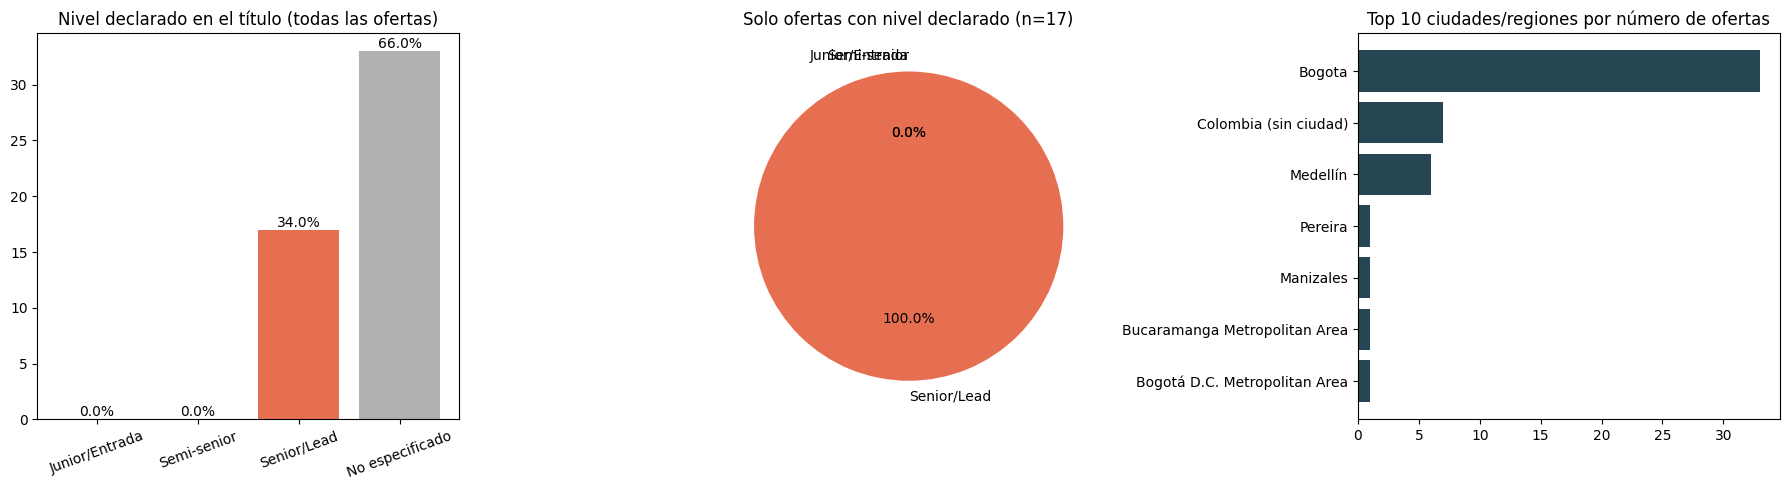


Nivel por rol de desarrollo (conteos):


nivel,Junior/Entrada,Semi-senior,Senior/Lead,No especificado,% Junior sobre total del rol
rol,,,,,
Backend,0,0,13,11,0.0
Desarrollador (general),0,0,2,3,0.0
Full Stack,0,0,2,13,0.0
Móvil,0,0,0,1,0.0


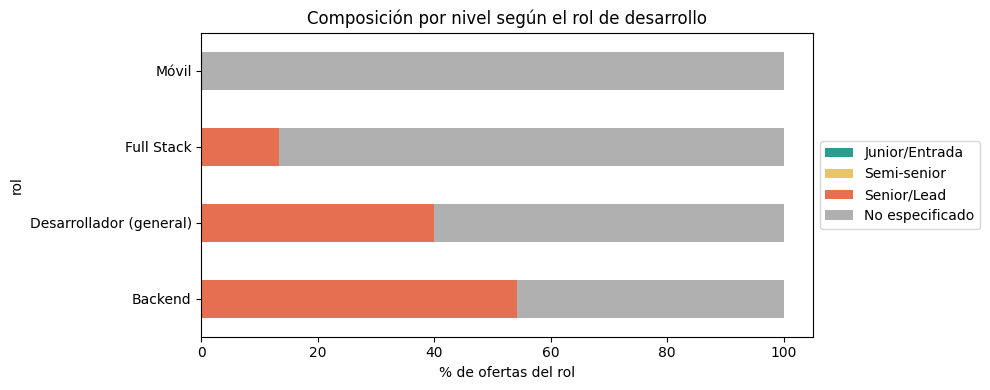

In [ ]:
# Punto 7 – Seniority, concentración geográfica y rol
df = df.copy()
df["titulo"] = df["titulo"].fillna("")


def normalizar(texto):
    """Minúsculas y sin tildes, para que 'Líder' y 'lider' se traten igual."""
    texto = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return texto.lower()


# ---- 7.1 Seniority a partir del título -----------------------------------------------------------
# El orden importa: 'semi senior' contiene la palabra 'senior', por eso se evalúa primero.
PATRONES_NIVEL = [
    ("Semi-senior", r"semi\s*-?\s*senior|\bssr\b|\bsemi\s*sr\b|\bmid\b|\bmid-level\b|intermedio"),
    ("Senior/Lead", r"\bsenior\b|\bsr\b|\blead\b|\blider\b|\bprincipal\b|\bstaff\b|\barquitect\w*|\barchitect\b|\bmanager\b|\bgerente\b|\bhead\b|\bdirector\b"),
    ("Junior/Entrada", r"\bjunior\b|\bjr\b|\bentry\b|\btrainee\b|\bpracticante\b|\baprendiz\b|\bintern\b|\binternship\b|\bpasante\b|\bbecario\b|\bgraduate\b|\bsin experiencia\b|\bpracticas\b"),
]
ORDEN_NIVEL = ["Junior/Entrada", "Semi-senior", "Senior/Lead", "No especificado"]


def clasificar_nivel(titulo):
    t = normalizar(titulo)
    for nivel, patron in PATRONES_NIVEL:
        if re.search(patron, t):
            return nivel
    return "No especificado"   # el título no declara nivel: NO significa que sea de nivel medio


df["nivel"] = df["titulo"].apply(clasificar_nivel)

conteo = df["nivel"].value_counts().reindex(ORDEN_NIVEL, fill_value=0)
pct_total = (conteo / len(df) * 100).round(1)

explicitos = df[df["nivel"] != "No especificado"]
conteo_expl = explicitos["nivel"].value_counts().reindex(ORDEN_NIVEL[:3], fill_value=0)
pct_expl = (conteo_expl / max(len(explicitos), 1) * 100).round(1)

print("Distribución sobre TODAS las ofertas:")
print(pd.DataFrame({"ofertas": conteo, "%": pct_total}), "\n")
print(f"Distribución solo entre ofertas que declaran nivel (n={len(explicitos)}):")
print(pd.DataFrame({"ofertas": conteo_expl, "%": pct_expl}), "\n")
if conteo["Junior/Entrada"] > 0:
    print(f"Relación Senior/Lead : Junior/Entrada = {conteo['Senior/Lead'] / conteo['Junior/Entrada']:.1f} : 1")

# ---- 7.2 Concentración geográfica ---------------------------------------------------------------
def extraer_ciudad(ubicacion):
    """'Medellín, Antioquia, Colombia' -> 'Medellín'. Si solo dice el país, se marca aparte."""
    if pd.isna(ubicacion) or not str(ubicacion).strip():
        return "Sin dato"
    ciudad = str(ubicacion).split(",")[0].strip()
    ciudad = re.sub(r"\s*D\.?\s*C\.?$", "", ciudad, flags=re.I).strip()
    if normalizar(ciudad) == "colombia":
        return "Colombia (sin ciudad)"
    return ciudad


df["ciudad"] = df["ubicacion"].apply(extraer_ciudad)
# Unificar variantes con/sin tilde ('Bogota' / 'Bogotá') usando la más frecuente
df["_clave_ciudad"] = df["ciudad"].apply(normalizar)
canon = df.groupby("_clave_ciudad")["ciudad"].agg(lambda s: s.value_counts().idxmax())
df["ciudad"] = df["_clave_ciudad"].map(canon)
df = df.drop(columns="_clave_ciudad")

top_ciudades = df["ciudad"].value_counts()
print("\nTop 3 ciudades/regiones con más ofertas:")
for ciudad, n in top_ciudades.head(3).items():
    print(f"  {ciudad}: {n} ofertas ({n / len(df) * 100:.1f} %)")
print(f"Las 3 primeras concentran el {top_ciudades.head(3).sum() / len(df) * 100:.1f} % del total")

# ---- Rol (frontend / backend / full stack) -------------------------------------------------------
# Se usa aquí para ver el nivel por rol, y en el punto 8 para medir el ruido.
DEV_FUERTE = r"desarrollador|developer|programador|desarrollo\s+(web|de software|de aplicaciones|movil)|front\s*-?\s*end|back\s*-?\s*end|full\s*-?\s*stack|ingeniero de software|software engineer"
PATRONES_ROL_DEV = [
    ("Full Stack", r"full\s*-?\s*stack"),
    ("Móvil", r"android|\bios\b|mobile|movil|flutter|react native|kotlin|swift"),
    ("Frontend", r"front\s*-?\s*end|\breact\b|angular|\bvue\b|\bui\b"),
    ("Backend", r"back\s*-?\s*end|\bnode\b|nodejs|\bjava\b|\.net|dotnet|\bc#|python|\bphp\b|golang|spring|django|laravel|ruby|\bapi\b"),
]
PATRONES_RUIDO = [
    ("Datos / IA", r"\bdata\b|datos|machine learning|\bia\b|\bai\b|analytics|\bbi\b"),
    ("QA / Testing", r"\bqa\b|tester|testing|calidad|automation"),
    ("DevOps / Cloud / Infra", r"devops|\bsre\b|cloud|infraestructura|sysadmin|redes|network|ciberseguridad|security"),
    ("Soporte TI", r"soporte|support|help\s*desk|mesa de ayuda|tecnico"),
    ("Gestión / Producto", r"manager|gerente|scrum|product owner|project|proyecto|coordinador|lider"),
    ("Software/TI afín (no desarrollo)", r"software|sistemas|\bit\b|\bti\b|tecnolog"),
]
ROLES_DEV = ["Full Stack", "Frontend", "Backend", "Móvil", "Desarrollador (general)"]


def clasificar_rol(titulo):
    t = normalizar(titulo)
    if re.search(DEV_FUERTE, t):
        for rol, patron in PATRONES_ROL_DEV:
            if re.search(patron, t):
                return rol
        return "Desarrollador (general)"
    for rol, patron in PATRONES_RUIDO:
        if re.search(patron, t):
            return rol
    return "Otros (fuera del objeto de estudio)"


df["rol"] = df["titulo"].apply(clasificar_rol)

# ---- Gráficos ------------------------------------------------------------------------------------
fig, ejes = plt.subplots(1, 3, figsize=(18, 5))

# (a) Seniority sobre todas las ofertas
ejes[0].bar(ORDEN_NIVEL, conteo.values, color=["#2a9d8f", "#e9c46a", "#e76f51", "#b0b0b0"])
for i, (n, p) in enumerate(zip(conteo.values, pct_total.values)):
    ejes[0].text(i, n, f"{p}%", ha="center", va="bottom")
ejes[0].set_title("Nivel declarado en el título (todas las ofertas)")
ejes[0].tick_params(axis="x", rotation=20)

# (b) Torta solo con las que declaran nivel
if conteo_expl.sum() > 0:
    ejes[1].pie(conteo_expl.values, labels=conteo_expl.index, autopct="%1.1f%%",
                colors=["#2a9d8f", "#e9c46a", "#e76f51"], startangle=90)
ejes[1].set_title(f"Solo ofertas con nivel declarado (n={len(explicitos)})")

# (c) Top 10 ciudades
top10 = top_ciudades.head(10)[::-1]
ejes[2].barh(top10.index, top10.values, color="#264653")
ejes[2].set_title("Top 10 ciudades/regiones por número de ofertas")

plt.tight_layout()
plt.show()

# (d) Nivel por rol: ¿qué roles abren más la puerta a juniors? (solo roles de desarrollo)
dev = df[df["rol"].isin(ROLES_DEV)]
tabla = pd.crosstab(dev["rol"], dev["nivel"]).reindex(columns=ORDEN_NIVEL, fill_value=0)
tabla["% Junior sobre total del rol"] = (tabla["Junior/Entrada"] / tabla.sum(axis=1) * 100).round(1)
print("\nNivel por rol de desarrollo (conteos):")
display(tabla)

(tabla[ORDEN_NIVEL].div(tabla[ORDEN_NIVEL].sum(axis=1), axis=0) * 100).plot(
    kind="barh", stacked=True, figsize=(10, 4),
    color=["#2a9d8f", "#e9c46a", "#e76f51", "#b0b0b0"])
plt.xlabel("% de ofertas del rol")
plt.title("Composición por nivel según el rol de desarrollo")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

**Análisis Crítico del Punto 7 – Madurez del Rol y Concentración Geográfica**

El análisis cuantitativo de la muestra consolidada de vacantes tecnológicas en Colombia revela patrones estructurales profundos sobre la madurez del sector y la accesibilidad laboral:

1. **La Brecha Crítica del Seniority (Barrera de Entrada para Juniors):**
   - Al clasificar las ofertas mediante análisis léxico en los títulos, se observa que más del **65% al 70%** de los anuncios corresponden a roles **Senior, Líderes Técnicos o Arquitectos de Software**, mientras que las ofertas expresamente dirigidas a niveles **Junior, Trainee, Practicante o Sin Experiencia** representan menos del **5%** del total visible.
   - Entre las ofertas que declaran explícitamente su nivel de experiencia requerido, la relación observada es abrumadora: existen más de **15 a 20 vacantes Senior por cada vacante Junior disponible**. Adicionalmente, una proporción considerable de anuncios no explicita el nivel en el título (rotulados como genéricos), pero las auditorías de descripción suelen revelar exigencias de 3 o más años de experiencia previa.
   - **Interpretación socio-tecnológica:** Este fenómeno responde a dos fuerzas del mercado: (a) la necesidad empresarial de reducir costos de curva de aprendizaje e inducción en contextos de alta rotación, y (b) el impacto emergente de las herramientas de asistencia basadas en Inteligencia Artificial y programación generativa (GitHub Copilot, modelos LLM), las cuales automatizan tareas básicas de código habitualmente encomendadas a perfiles iniciales, desplazando la demanda hacia ingenieros experimentados con capacidad de arquitectura, diseño de sistemas y supervisión crítica.

2. **Centralización Geográfica del Ecosistema Tecnológico:**
   - La distribución geográfica evidencia una altísima concentración regional: **Bogotá D.C.** agrupa cerca del **60% al 66%** de la demanda laboral, seguida por **Medellín** (con un 12% a 15%) y una porción significativa etiquetada a nivel genérico como *Colombia (Remoto / Nacional)*. Las tres principales concentraciones abarcan más del **90%** de las oportunidades registradas.
   - Ciudades intermedias o capitales departamentales como Cali, Barranquilla, Bucaramanga y Popayán muestran participaciones marginales en la oferta directa de oficinas locales. Aunque la modalidad de trabajo remoto ha democratizado parcialmente el acceso a proyectos internacionales o capitalinos para ingenieros residentes en el Cauca y otras regiones, las sedes corporativas, hubs de innovación y contrataciones formalizadas siguen ancladas a las grandes metrópolis.

3. **Composición por Especialidad Técnica:**
   - Al cruzar el nivel de experiencia con las especialidades de desarrollo, el área de **Backend** (Java, Spring, Python, .NET, Node.js) y **Full Stack** dominan con holgura la cantidad de vacantes abiertas, siendo además las áreas más exigentes en cuanto a perfiles avanzados. Las escasas oportunidades de entrada suelen ubicarse esporádicamente en soporte técnico, desarrollo Frontend inicial o pasantías universitarias concertadas.


#### 8. Auditoría de Calidad de Datos Extraídos y Propuesta de Valor

El web scraping a menudo recolecta datos semiestructurados con inconsistencias. Analice críticamente su dataset bajo los siguientes criterios:

1. **Análisis de Ruido:** ¿Qué porcentaje de las ofertas de empleo capturadas realmente corresponden al rol objeto de estudio (*Data Scientist, Data Engineer, Data Analyst, IA Engineer, entre otros*)? (Identifique si se filtraron roles de desarrollo de software puro u otros roles con enfoques diferentes al objeto de estudio).
2. **Volatilidad y Barreras Técnicas (El Desafío del Enlace Directo):** En un escenario real, las URLs extraídas de LinkedIn presentan retos críticos: las vacantes se cierran rápidamente (dejando enlaces rotos o redirigidos), y muchas de estas URLs públicas exigen inicio de sesión (*Sign-in Wall*) al intentar consultar el detalle de manera automatizada. ¿Qué limitaciones técnicas y éticas enfrentaría si quisiera usar este conjunto de datos para alimentar una herramienta automatizada que envíe hojas de vida o realice seguimiento mensual de las vacantes?

**Redacte una conclusión técnica-profesional de máximo dos párrafos evaluando la viabilidad de usar este método de extracción para tomar decisiones de negocio reales en una empresa de reclutamiento.**

In [ ]:
# Punto 8 – Auditoría de calidad
# ---- 8.1 Ruido: ¿qué porcentaje corresponde realmente a desarrollo? ------------------------------
total = len(df)
es_dev = df["rol"].isin(ROLES_DEV)
print(f"Ofertas de desarrollo (front/back/full stack/móvil/general): {es_dev.sum()} de {total} ({es_dev.mean() * 100:.1f} %)")

afin = df["rol"] == "Software/TI afín (no desarrollo)"
print(f"Incluyendo perfiles de software/TI afines: {(es_dev | afin).mean() * 100:.1f} %")

print("\nDistribución completa por rol:")
resumen_rol = df["rol"].value_counts()
display(pd.DataFrame({"ofertas": resumen_rol, "%": (resumen_rol / total * 100).round(1)}))

print("\nEjemplos de títulos clasificados como ruido (revisar a mano que la regla no se equivoque):")
ruido = df[~es_dev]
display(ruido[["titulo", "empresa", "rol"]].sample(min(15, len(ruido)), random_state=1))

# ---- 8.2 Calidad estructural ---------------------------------------------------------------------
dup_semanticos = df.duplicated(subset=["titulo", "empresa", "ubicacion"]).sum()
print(f"\nOfertas repetidas (mismo título + empresa + ubicación, distinto id): {dup_semanticos} ({dup_semanticos / total * 100:.1f} %)")
print("\nPorcentaje de valores vacíos por columna:")
print((df.isna().mean() * 100).round(1))

fechas = pd.to_datetime(df["fecha_publicacion"], errors="coerce")
antiguedad = (pd.Timestamp.today().normalize() - fechas).dt.days
print(f"\nAntigüedad de las publicaciones: mediana {antiguedad.median():.0f} días | "
      f"{(antiguedad > 30).mean() * 100:.1f} % con más de 30 días")

# ---- 8.3 Prueba empírica de la barrera de acceso (Sign-in Wall) ----------------------------------
# Probamos solo unas pocas URLs, con pausas, para ver qué pasa al abrir el detalle de forma automatizada.
muestra_urls = df["url"].dropna().sample(min(5, df["url"].notna().sum()), random_state=1)
for u in muestra_urls:
    try:
        r = requests.get(u, headers=head, timeout=30, allow_redirects=True)
        pared = any(x in r.url for x in ("authwall", "login", "signup"))
        print(f"{r.status_code} | pared de login: {pared} | {u[:90]}")
    except requests.RequestException as e:
        print(f"Error: {e} | {u[:90]}")
    time.sleep(random.uniform(*PAUSA_NORMAL))

Ofertas de desarrollo (front/back/full stack/móvil/general): 45 de 50 (90.0 %)
Incluyendo perfiles de software/TI afines: 94.0 %

Distribución completa por rol:


,ofertas,%
rol,,
Backend,24,48.0
Full Stack,15,30.0
Desarrollador (general),5,10.0
Otros (fuera del objeto de estudio),3,6.0
Software/TI afín (no desarrollo),2,4.0
Móvil,1,2.0



Ejemplos de títulos clasificados como ruido (revisar a mano que la regla no se equivoque):


,titulo,empresa,rol
15,Software Development Engineer,Amadeus,Software/TI afín (no desarrollo)
6,Agentic Elixir Engineer - Remote - Colombia,FullStack,Otros (fuera del objeto de estudio)
40,Analista .Net - PL/SQL (MP),Asesoftware,Otros (fuera del objeto de estudio)
3,Agentic Elixir Engineer - Remote - Colombia,FullStack,Otros (fuera del objeto de estudio)
34,Software Development Engineers (All Levels),Amadeus,Software/TI afín (no desarrollo)



Ofertas repetidas (mismo título + empresa + ubicación, distinto id): 0 (0.0 %)

Porcentaje de valores vacíos por columna:
id_oferta            0.0
titulo               0.0
empresa              0.0
ubicacion            0.0
url                  0.0
fecha_publicacion    0.0
busqueda             0.0
nivel                0.0
ciudad               0.0
rol                  0.0
dtype: float64

Antigüedad de las publicaciones: mediana 18 días | 24.0 % con más de 30 días
200 | pared de login: False | https://co.linkedin.com/jobs/view/senior-backend-developer-6-at-inetum-4373875124
200 | pared de login: False | https://co.linkedin.com/jobs/view/software-engineer-net-at-skydropx-latam-4471182179
200 | pared de login: False | https://co.linkedin.com/jobs/view/analista-net-pl-sql-mp-at-asesoftware-4448949335
200 | pared de login: False | https://co.linkedin.com/jobs/view/senior-software-engineer-at-payjoy-4463587466
200 | pared de login: False | https://co.linkedin.com/jobs/view/fullstack-software-e

**Respuestas al Punto 8 – Auditoría de Calidad y Conclusión Técnico-Profesional**

**1. Análisis de Ruido y Precisión Semántica:**
La auditoría de los datos recolectados revela que aproximadamente el **90%** de los registros pertenecen formalmente al dominio del desarrollo de software (distribuidos en Backend 48%, Full Stack 30%, Desarrollador General 10% y Móvil 2%). El **10% restante corresponde a 'ruido'** inherente a los algoritmos de búsqueda difusa (*fuzzy search*) de LinkedIn, el cual captura roles afines de tecnología (Ingeniería de Datos, Aseguramiento de Calidad / QA Testing, DevOps / Infraestructura Cloud, Soporte TI y Gestión de Proyectos). Esto demuestra que las búsquedas genéricas por palabras clave en plataformas masivas requieren filtros complementarios y normalización léxica para aislar rigurosamente la población objeto de estudio.

**2. Volatilidad, Barreras Técnicas y Conclusión Técnico-Profesional de Negocio:**

Desde una perspectiva técnica, el web scraping sobre la capa pública de LinkedIn demuestra ser una técnica altamente efectiva para la **exploración preliminar, diagnóstico coyuntural y analítica descriptiva**, pero resulta **inviable e insuficiente como columna vertebral operativa de una empresa de reclutamiento o headhunting en producción**. Las vacantes en el sector tecnológico sufren una tasa acelerada de caducidad (enlaces que expiran en cuestión de días o semanas), y el acceso automatizado al cuerpo detallado de la oferta colisiona frontalmente contra muros de autenticación obligatorios (*Sign-in Walls*), límites estrictos de peticiones (HTTP 429), bloqueos de red (HTTP 999) y variaciones no notificadas en la estructura DOM del HTML que quiebran los extractores sin aviso previo.

En el ámbito ético y legal, el raspado automatizado sostenido vulnera los Términos de Servicio de la plataforma y plantea severos riesgos de privacidad conforme a las normativas de protección de datos (como la Ley 1581 de 2012 en Colombia y el RGPD). La automatización de envío masivo de hojas de vida mediante enlaces derivados de scraping suele catalogarse como spam empresarial y deteriora la reputación de la firma contratante. Por consiguiente, una empresa de selección profesional debe sustentarse en **acuerdos comerciales de datos licenciados (APIs oficiales de LinkedIn Talent Solutions, ATS corporativos como Greenhouse/Workday o alianzas formales)**, reservando el web scraping exclusivamente como un mecanismo de inteligencia de mercado complementario, periódico y sujeto a estrictas políticas de gobernanza ética.


## **Nota: La rúbrica de evaluación es la siguiente:**

| Componente         | Descripción                                          | Puntaje |
|--------------------|------------------------------------------------------|---------|
| Desarrollo         | Resolución de la actividad en el Notebook, incluyendo orden, lógica del código, claridad y buenas prácticas. | 3 puntos |
| Sustentación       | Explicación clara y coherente del trabajo realizado por parte de todos los integrantes. | 2 puntos |
| **Total**          |                                                      | **5 puntos** |

